# 01 · Data check: NEU steel surface defects

**Goal:** make sure the dataset is what we think it is before anything else uses it. How many images per class, what size and colour mode they are, and whether any image appears twice.

**Inputs:** the NEU surface defect database, Kaggle mirror `kaustubhdikshit/neu-surface-defect-database` (NEU-DET layout).

**Outputs:**
- `data/all_images.csv`: one row per image, the list every later notebook reads
- `outputs/results/data_check_summary.json`: the numbers quoted in our log and report
- `outputs/results/pip_freeze_kaggle.txt`: exact library versions of this run
- `outputs/figures/data_01_one_per_class.png`

## Setup

The same notebook runs on Kaggle and on a laptop. On Kaggle the dataset is mounted read-only under `/kaggle/input`, and whatever we write to `/kaggle/working` can be downloaded after the run. We keep the same `data/` and `outputs/` folders in both places so the downloaded files drop straight into the project folder.

In [1]:
import hashlib
import json
import platform
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

SEED = 42
ON_KAGGLE = Path("/kaggle/input").exists()

if ON_KAGGLE:
    PROJECT = Path("/kaggle/working")
    DATA_ROOT = next(Path("/kaggle/input").rglob("NEU-DET")).parent
else:
    PROJECT = Path.cwd().parent
    DATA_ROOT = PROJECT / "data" / "raw"

FIG_DIR = PROJECT / "outputs" / "figures"
RES_DIR = PROJECT / "outputs" / "results"
for folder in (FIG_DIR, RES_DIR, PROJECT / "data"):
    folder.mkdir(parents=True, exist_ok=True)

print("running on Kaggle:", ON_KAGGLE)
print("dataset folder:", DATA_ROOT)

running on Kaggle: True
dataset folder: /kaggle/input/datasets/kaustubhdikshit/neu-surface-defect-database


## Environment

We note the versions now so every later result can be tied to an exact setup. We also check that TensorFlow sees the GPU, because the models are trained on it in notebook 04.

In [2]:
import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")
env = {
    "python": platform.python_version(),
    "tensorflow": tf.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "gpus": [gpu.name for gpu in gpus],
}
if gpus:
    env["gpu_model"] = tf.config.experimental.get_device_details(gpus[0]).get("device_name", "unknown")
print(json.dumps(env, indent=2))

freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
(RES_DIR / "pip_freeze_kaggle.txt").write_text(freeze)

{
  "python": "3.13.15",
  "tensorflow": "2.20.0",
  "numpy": "2.1.3",
  "pandas": "2.3.3",
  "gpus": [
    "/physical_device:GPU:0",
    "/physical_device:GPU:1"
  ],
  "gpu_model": "Tesla T4"
}


18034

## Find every image

NEU-DET keeps its images in `train` and `validation` folders and adds XML box annotations for object detection. We only need the class of each image, which is the start of its file name (`crazing_12.jpg` is crazing). So we collect the images from both folders, ignore the boxes, and make our own split later in notebook 03.

For every image we also record two fingerprints:
- `file_md5`: a hash of the file bytes, which catches exact copies of a file.
- `pixel_md5`: a hash of the decoded pixels, which also catches the same picture saved twice in different files.

In [3]:
IMAGE_EXT = {".jpg", ".jpeg", ".bmp", ".png"}


def label_from_name(path):
    # "rolled-in_scale_17.jpg" -> "rolled-in_scale"
    return path.stem.rsplit("_", 1)[0]


rows = []
for path in sorted(p for p in DATA_ROOT.rglob("*") if p.suffix.lower() in IMAGE_EXT):
    rel = path.relative_to(DATA_ROOT)
    with Image.open(path) as im:
        pixels = np.asarray(im)
        rows.append({
            "filepath": rel.as_posix(),
            "label": label_from_name(path),
            "source_folder": next((part for part in rel.parts if part in ("train", "validation")), ""),
            "width": im.width,
            "height": im.height,
            "mode": im.mode,
            "format": im.format,
            "file_md5": hashlib.md5(path.read_bytes()).hexdigest(),
            "pixel_md5": hashlib.md5(np.asarray(im.convert("L")).tobytes()).hexdigest(),
            "channels_identical": bool(pixels.ndim == 2 or np.all(pixels[..., 0] == pixels[..., 1]) and np.all(pixels[..., 1] == pixels[..., 2])),
        })

df = pd.DataFrame(rows)
n_xml = sum(1 for _ in DATA_ROOT.rglob("*.xml"))
print(f"{len(df)} images, {n_xml} XML annotation files")
df.head()

1800 images, 1800 XML annotation files


,filepath,label,source_folder,width,height,mode,format,file_md5,pixel_md5,channels_identical
0,NEU-DET/train/images/crazing/crazing_1.jpg,crazing,train,200,200,RGB,JPEG,163c64172b0f5ada1b9b4780a9dec785,2e6a9912cba076247d418ca165edc50f,True
1,NEU-DET/train/images/crazing/crazing_10.jpg,crazing,train,200,200,RGB,JPEG,944878044e9e2801e73e14bda290bc19,825d7b185a4e1a5eb9fe34bb053f7957,True
2,NEU-DET/train/images/crazing/crazing_100.jpg,crazing,train,200,200,RGB,JPEG,697327e20ec0fd6a0f852225e88939ce,4e85f48a05c8a06185c224c58125723c,True
3,NEU-DET/train/images/crazing/crazing_101.jpg,crazing,train,200,200,RGB,JPEG,cac55ab2a43895a925cbdf0c5245e5aa,1baad4c4d30cf6d9be02549386fc5773,True
4,NEU-DET/train/images/crazing/crazing_102.jpg,crazing,train,200,200,RGB,JPEG,425974aadacb12ae06b7c9da39b25bb8,29fefd068b6d870735b1ce3aa243ba80,True


## Images per class

NEU should have 300 images in each of 6 classes. A missing or extra class here would mean a broken mirror. The second table shows how the mirror spread each class over its own train and validation folders.

In [4]:
per_class = df["label"].value_counts().sort_index()
print(per_class.to_string())
pd.crosstab(df["label"], df["source_folder"], margins=True)

label
crazing            300
inclusion          300
patches            300
pitted_surface     300
rolled-in_scale    300
scratches          300


source_folder,train,validation,All
label,,,
crazing,240,60,300
inclusion,240,60,300
patches,240,60,300
pitted_surface,240,60,300
rolled-in_scale,240,60,300
scratches,240,60,300
All,1440,360,1800


## Size, colour mode and file format

This decides how we load the images. Our CNN from scratch can take one grayscale channel; ImageNet models expect three. If an image is stored as RGB but its three channels are identical, it is really grayscale saved in a colour file.

In [5]:
sizes = df.groupby(["width", "height"]).size().rename("images")
modes = df["mode"].value_counts()
formats = df["format"].value_counts()
print(sizes.to_string(), "\n")
print(modes.to_string(), "\n")
print(formats.to_string(), "\n")
print("images whose colour channels are identical:", int(df["channels_identical"].sum()), "of", len(df))

width  height
200    200       1800 

mode
RGB    1800 

format
JPEG    1800 

images whose colour channels are identical: 1800 of 1800


## Exact duplicates

If the same picture sits in two places and one copy lands in training while the other lands in test, the test score is inflated, because the model has already seen that exact image. We group images by their fingerprints and list every group with more than one member.

In [6]:
file_dups = df[df.duplicated("file_md5", keep=False)].sort_values("file_md5")
pixel_dups = df[df.duplicated("pixel_md5", keep=False)].sort_values("pixel_md5")
n_file_groups = file_dups["file_md5"].nunique()
n_pixel_groups = pixel_dups["pixel_md5"].nunique()
print("duplicate groups by file bytes:", n_file_groups, f"({len(file_dups)} images)")
print("duplicate groups by pixels:   ", n_pixel_groups, f"({len(pixel_dups)} images)")
pixel_dups[["filepath", "label", "pixel_md5"]]

duplicate groups by file bytes: 1 (2 images)
duplicate groups by pixels:    1 (2 images)


,filepath,label,pixel_md5
483,NEU-DET/train/images/patches/patches_101.jpg,patches,f1cc1a5ff49dbd08ef7329d00f2253d9
487,NEU-DET/train/images/patches/patches_105.jpg,patches,f1cc1a5ff49dbd08ef7329d00f2253d9


## One image per class

A first look at what the classes are. We take the first file of each class by name, so the figure is the same every run.

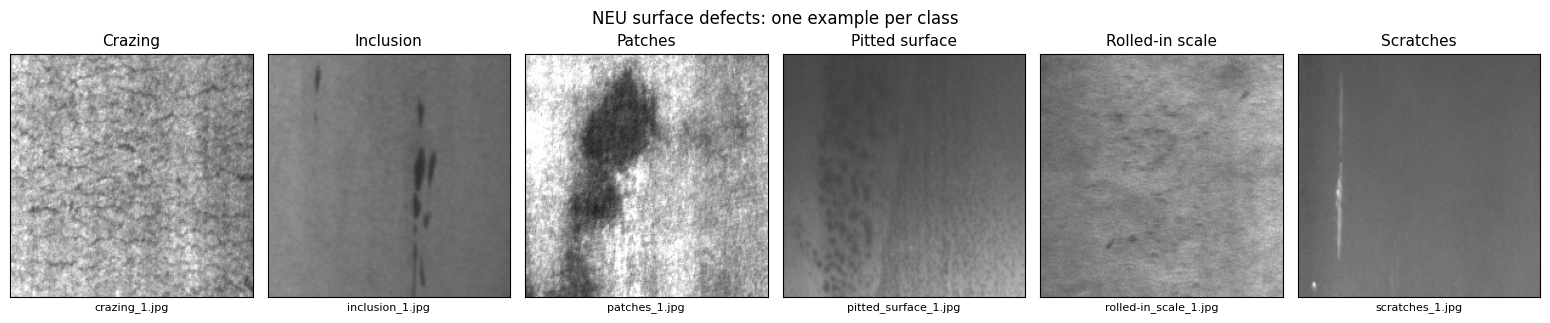

In [7]:
CLASS_NAMES = {
    "crazing": "Crazing",
    "inclusion": "Inclusion",
    "patches": "Patches",
    "pitted_surface": "Pitted surface",
    "rolled-in_scale": "Rolled-in scale",
    "scratches": "Scratches",
}

classes = sorted(df["label"].unique())
fig, axes = plt.subplots(1, len(classes), figsize=(2.6 * len(classes), 3.1))
for ax, label in zip(axes, classes):
    first = df[df["label"] == label].sort_values("filepath").iloc[0]
    with Image.open(DATA_ROOT / first["filepath"]) as im:
        ax.imshow(im.convert("L"), cmap="gray", vmin=0, vmax=255)
    ax.set_title(CLASS_NAMES.get(label, label), fontsize=11)
    ax.set_xlabel(Path(first["filepath"]).name, fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("NEU surface defects: one example per class", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "data_01_one_per_class.png", dpi=150)
plt.show()

## Save the master table and the summary

`data/all_images.csv` is the one list of images that every later notebook reads, so they all agree on what the dataset is. The summary JSON holds the numbers we quote in `LOG.md` and the report.

In [8]:
df.to_csv(PROJECT / "data" / "all_images.csv", index=False)

summary = {
    "data_source": "kaggle:kaustubhdikshit/neu-surface-defect-database (NEU-DET layout)",
    "n_images": int(len(df)),
    "n_classes": int(df["label"].nunique()),
    "images_per_class": {k: int(v) for k, v in per_class.items()},
    "images_per_source_folder": {k: int(v) for k, v in df["source_folder"].value_counts().items()},
    "sizes": {f"{w}x{h}": int(n) for (w, h), n in sizes.items()},
    "modes": {k: int(v) for k, v in modes.items()},
    "formats": {k: int(v) for k, v in formats.items()},
    "channels_identical": int(df["channels_identical"].sum()),
    "xml_annotation_files": int(n_xml),
    "duplicate_groups_file_md5": int(n_file_groups),
    "duplicate_groups_pixel_md5": int(n_pixel_groups),
    "images_in_pixel_duplicate_groups": int(len(pixel_dups)),
    "environment": env,
}
(RES_DIR / "data_check_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "data_source": "kaggle:kaustubhdikshit/neu-surface-defect-database (NEU-DET layout)",
  "n_images": 1800,
  "n_classes": 6,
  "images_per_class": {
    "crazing": 300,
    "inclusion": 300,
    "patches": 300,
    "pitted_surface": 300,
    "rolled-in_scale": 300,
    "scratches": 300
  },
  "images_per_source_folder": {
    "train": 1440,
    "validation": 360
  },
  "sizes": {
    "200x200": 1800
  },
  "modes": {
    "RGB": 1800
  },
  "formats": {
    "JPEG": 1800
  },
  "channels_identical": 1800,
  "xml_annotation_files": 1800,
  "duplicate_groups_file_md5": 1,
  "duplicate_groups_pixel_md5": 1,
  "images_in_pixel_duplicate_groups": 2,
  "environment": {
    "python": "3.13.15",
    "tensorflow": "2.20.0",
    "numpy": "2.1.3",
    "pandas": "2.3.3",
    "gpus": [
      "/physical_device:GPU:0",
      "/physical_device:GPU:1"
    ],
    "gpu_model": "Tesla T4"
  }
}


## What we found

- **1,800 images, 300 in each of the 6 classes**, as the NEU description says. The mirror's own `train` / `validation` folders (1,440 / 360 images) are ignored; notebook 02 makes our own split.
- **Every file is a 200 × 200 px JPEG.** They are stored as RGB, but in every single image the three colour channels are identical. So these are grayscale pictures saved in a colour format. Our own CNN reads them as one grayscale channel; for ImageNet models we repeat that channel three times.
- **One picture appears twice:** `patches_101.jpg` and `patches_105.jpg` are byte-for-byte the same file, both labelled patches. Notebook 02 keeps both copies in the same part of the split, so one can never be in training while the other is in test.
- The XML box annotations (1,800 files) are for object detection. We don't use them.